# NB17 — FOD Detection: Aviation Variant (R21, internal narrative)
Synthetic airside scenes (tarmac texture, lane markings) with foreign objects
(bolts, wrench-like shapes, fragments); same detector + mAP machinery as NB15.
Gate: mAP50 ≥ 0.60. Workstation (guarded): YOLO on real FOD-A. Demo reel saved.

In [1]:
import importlib.util
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter, label, median_filter

DATA = Path("../../data")
IMG = 128

def tarmac(seed):
    r = np.random.default_rng(seed)
    t = gaussian_filter(r.normal(0, 1, (IMG, IMG)), 1.2) * 0.05 + 0.22
    t += (r.random((IMG, IMG)) < 0.01) * 0.12                      # aggregate speckle
    x0 = int(r.integers(30, 90))
    t[:, x0:x0 + 4] = 0.85                                          # lane marking
    return np.clip(t, 0, 1), x0

def add_fod(img, r):
    im = img.copy()
    kind = ["bolt", "wrench", "fragment"][int(r.integers(0, 3))]
    cx, cy = int(r.integers(12, IMG - 12)), int(r.integers(12, IMG - 12))
    if kind == "bolt":
        yy, xx = np.mgrid[0:IMG, 0:IMG]
        im[((xx - cx) ** 2 + (yy - cy) ** 2) < 16] = 0.75
    elif kind == "wrench":
        im[cy - 2:cy + 2, max(cx - 9, 0):cx + 9] = 0.7
        im[cy - 4:cy + 4, max(cx - 11, 0):cx - 7] = 0.7
    else:
        h, w = int(r.integers(3, 7)), int(r.integers(4, 9))
        im[cy:cy + h, cx:cx + w] = 0.65
    ys, xs = np.where(np.abs(im - img) > 0.02)      # GT = actual changed pixels
    return im, {"bbox": [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())],
                "kind": kind}

def detect(img, seed_contrast=0.2, k_lo=1.5, min_area=12, dil=2, ext=0.3):
    """Column-median removes the lane marking; hysteresis (absolute-contrast seed,
    statistical grow); boxes refit on pixels above ext*peak."""
    from scipy.ndimage import binary_dilation
    flat = img - np.median(img, axis=0, keepdims=True)
    resid = gaussian_filter(np.abs(flat - median_filter(flat, size=21)), 0.8)
    mu, sd = resid.mean(), resid.std()
    lab, n = label(binary_dilation(resid > mu + k_lo * sd, iterations=dil))
    out = []
    for i in range(1, n + 1):
        comp = lab == i
        if comp.sum() < min_area:
            continue
        peak = float(resid[comp].max())
        if peak < seed_contrast:
            continue
        core = comp & (resid > ext * peak)
        ys, xs = np.where(core if core.any() else comp)
        out.append({"bbox": [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())],
                    "score": peak})
    return out

def iou(a, b):
    ix0, iy0 = max(a[0], b[0]), max(a[1], b[1])
    ix1, iy1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix1 - ix0) * max(0, iy1 - iy0)
    ar = lambda z: max((z[2] - z[0]) * (z[3] - z[1]), 1e-9)
    return inter / (ar(a) + ar(b) - inter)

def map50(all_preds, all_gts):
    recs = sorted([(p["score"], i, p["bbox"]) for i, ps in enumerate(all_preds) for p in ps],
                  reverse=True)
    n_gt = sum(map(len, all_gts))
    matched = [set() for _ in all_gts]
    tp = np.zeros(len(recs)); fp = np.zeros(len(recs))
    for r, (s, i, bb) in enumerate(recs):
        cand = [(iou(bb, g["bbox"]), j) for j, g in enumerate(all_gts[i]) if j not in matched[i]]
        best, bj = max(cand, default=(0.0, -1))
        if best >= 0.5:
            tp[r] = 1; matched[i].add(bj)
        else:
            fp[r] = 1
    ctp, cfp = np.cumsum(tp), np.cumsum(fp)
    rec, prec = ctp / max(n_gt, 1), ctp / np.maximum(ctp + cfp, 1e-9)
    return float(np.mean([prec[rec >= t].max() if (rec >= t).any() else 0.0
                          for t in np.linspace(0, 1, 101)]))

## Build set, evaluate, save demo reel

FOD mAP@0.5 = 1.000


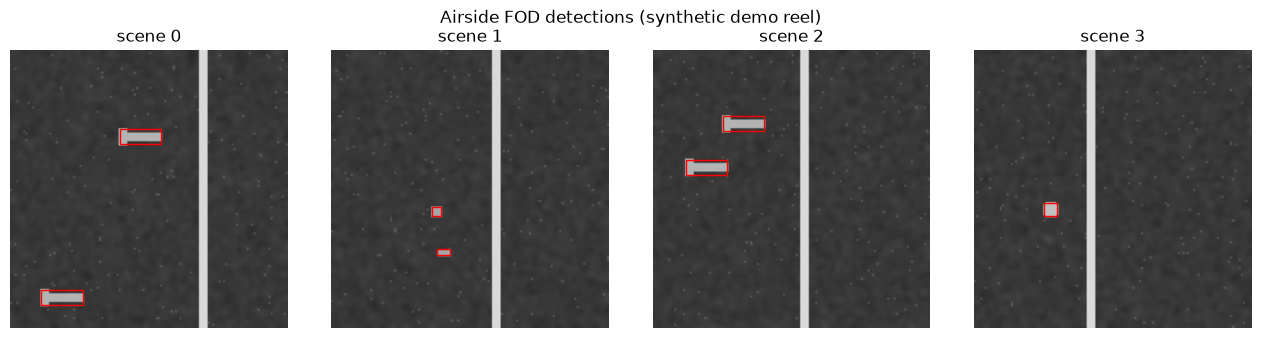

SKIP ultralytics (workstation) — real FOD-A per SOP; demo reel saved for internal narrative
NB17 complete.


In [2]:
imgs, gts = [], []
for i in range(40):
    r = np.random.default_rng(6000 + i)
    img, _ = tarmac(6000 + i)
    boxes = []
    for _ in range(int(r.integers(1, 3))):
        img, g = add_fod(img, r)
        boxes.append(g)
    imgs.append(img); gts.append(boxes)

preds = [detect(im) for im in imgs]
ap = map50(preds, gts)
print(f"FOD mAP@0.5 = {ap:.3f}")
assert ap >= 0.60, "FOD mAP below gate"

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, i in zip(axes, range(4)):
    ax.imshow(imgs[i], cmap="gray", vmin=0, vmax=1)
    for d in preds[i]:
        x0, y0, x1, y1 = d["bbox"]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="red"))
    ax.set_title(f"scene {i}"); ax.axis("off")
plt.suptitle("Airside FOD detections (synthetic demo reel)")
plt.tight_layout(); plt.savefig(DATA / "interim/nb17_fod_reel.png", dpi=110); plt.show()

json.dump({"map50": round(ap, 4),
           "samples": [{"image_id": i, "gt": gts[i], "pred": preds[i]} for i in range(8)]},
          open(DATA / "processed/nb17_fod.json", "w"), indent=1)
if importlib.util.find_spec("ultralytics"):
    print("ultralytics present → fine-tune on real FOD-A (SOP runbook)")
else:
    print("SKIP ultralytics (workstation) — real FOD-A per SOP; demo reel saved for internal narrative")
print("NB17 complete.")